In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image

In [3]:
img = cv2.imread("sample_image.jpg", cv2.IMREAD_GRAYSCALE)

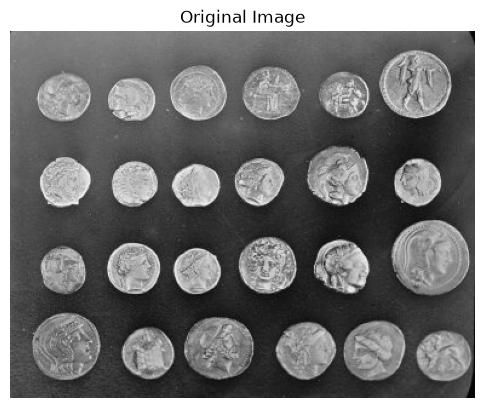

In [4]:
plt.figure(figsize=(6,5))
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

In [5]:
# 1. Laplacian filter manual
lap_kernal = np.array([[0,1,0],
                      [1,-4,1],
                      [0,1,0]], dtype=np.float32)

In [6]:
lap_manual = cv2.filter2D(img.astype(np.float32), -1, lap_kernal)
lap_kernal_display = cv2.convertScaleAbs(lap_manual)

In [7]:
# 2. Laplacian filter automatic
lap_cv2 = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
lap_cv2_display = (cv2.convertScaleAbs(lap_cv2))

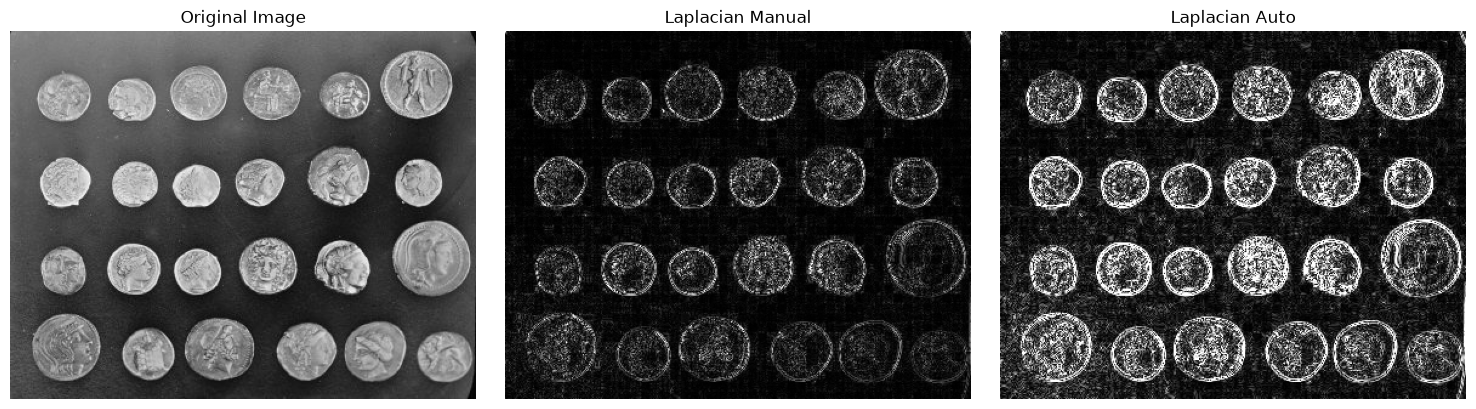

In [8]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(lap_kernal_display, cmap="gray")
plt.title("Laplacian Manual")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(lap_cv2_display, cmap="gray")
plt.title("Laplacian Auto")
plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# 3. Sobel filter manual
sobel_kernal_x = np.array([[-1,0,1],
                          [-2,0,2],
                          [-1,0,1]], dtype=np.float32)

sobel_kernal_y = np.array([[-1,-2,-1],
                          [0,0,0],
                          [1,2,1]], dtype=np.float32)

In [10]:
sobel_x_manual = cv2.filter2D(img.astype(np.float32), -1, sobel_kernal_x)
sobel_y_manual = cv2.filter2D(img.astype(np.float32), -1, sobel_kernal_y)
sobel_manual_magnitude = cv2.magnitude(sobel_x_manual, sobel_y_manual)
sobel_manual_display = (cv2.convertScaleAbs(sobel_manual_magnitude))

In [11]:
# 4. Sobel filter automatic
sobel_x_cv2 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_cv2 = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_cv2_magnitude = cv2.magnitude(sobel_x_cv2, sobel_y_cv2)
sobel_cv2_display = cv2.convertScaleAbs(sobel_cv2_magnitude)

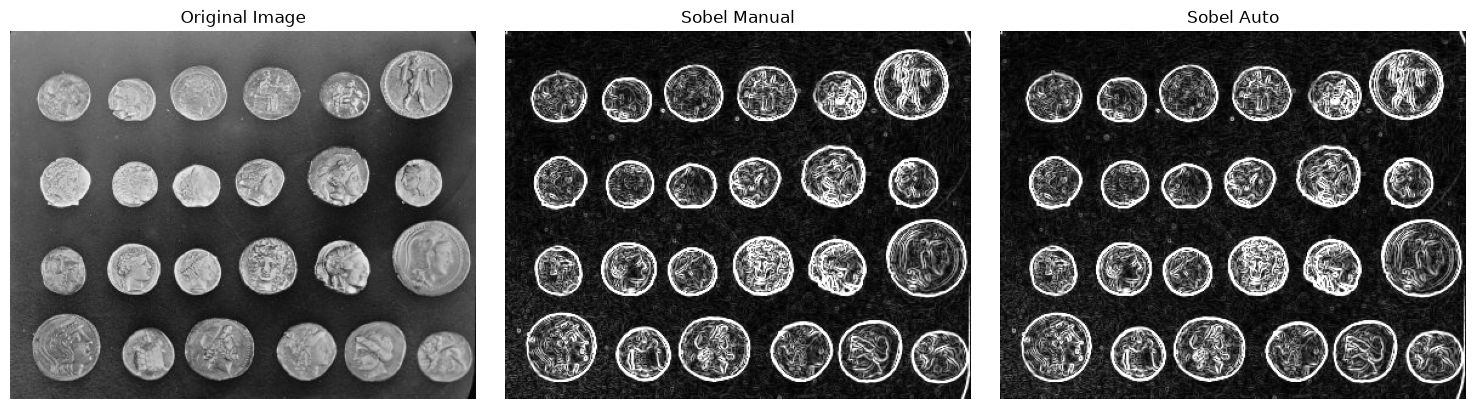

In [12]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sobel_manual_display, cmap="gray")
plt.title("Sobel Manual")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sobel_cv2_display, cmap="gray")
plt.title("Sobel Auto")
plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Sharpening Manual
sharpening_kernal = np.array([[0,-1,0],
                              [-1,5,-1],
                              [0,-1,0]], dtype=np.float32)

sharpened_manual = cv2.filter2D(img.astype(np.float32), -1, sharpening_kernal)
sharpening_manual_display = np.clip(sharpened_manual, 0, 255).astype(np.uint8)

# Sharpening Auto
lap = cv2.Laplacian(img.astype(np.float32), cv2.CV_32F, ksize=1)
sharpening_cv2_display = np.clip(img.astype(np.float32) - lap, 0, 255).astype(np.uint8)

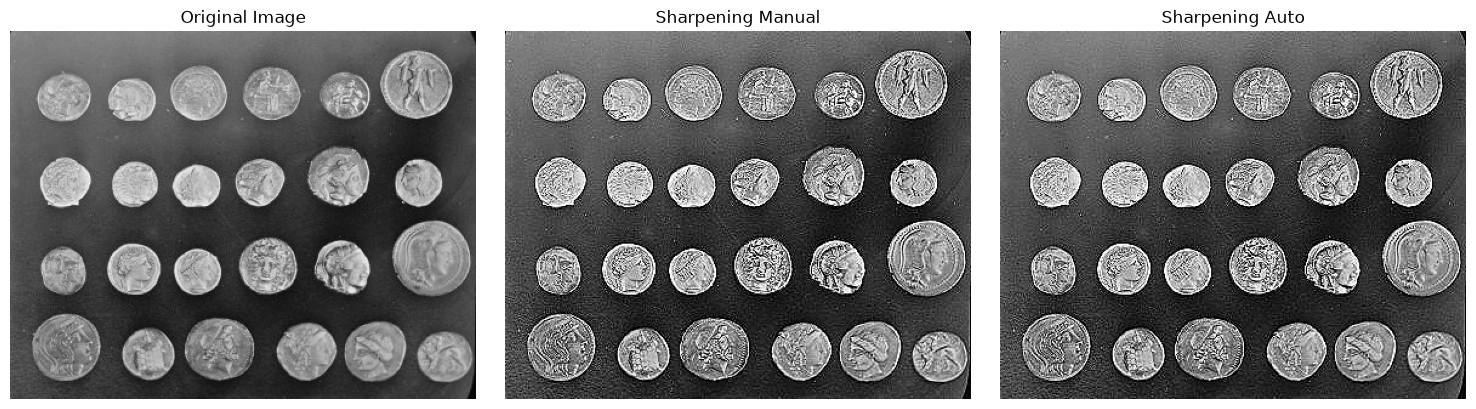

In [14]:
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sharpening_manual_display, cmap="gray", vmin=0, vmax=255)
plt.title("Sharpening Manual")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sharpening_cv2_display, cmap="gray", vmin=0, vmax=255)
plt.title("Sharpening Auto")
plt.axis("off")

plt.tight_layout()
plt.show()